# Demo: Limpieza y análisis de datos con **Python + Pandas**
**Objetivo didáctico:** mostrar un flujo completo (carga → diagnóstico → limpieza → validación → análisis básico) y evidenciar el *antes* y *después* del tratamiento de datos.

> Este cuaderno usa un dataset **sintético** (generado aquí mismo) con errores comunes: valores faltantes, duplicados, tipos inconsistentes, fechas mal formateadas, textos con espacios/casos distintos, etc.


In [1]:
# 1) Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)


## 2) Dataset de ejemplo (con problemas intencionales)

In [4]:
# Creamos un dataset con problemas típicos de calidad
raw_data = [
    {"FacturaID": "F-0001", "Fecha": "2026-02-01", "Cliente": "  ana perez ", "Ciudad": "guatemala", "Categoria": "Bebidas", "Producto": "Café", "Cantidad": "2", "PrecioUnitario": "Q 18.50", "Descuento": None},
    {"FacturaID": "F-0002", "Fecha": "01/02/2026", "Cliente": "Juan  López", "Ciudad": "Guatemala ", "Categoria": "BEBIDAS", "Producto": "Te", "Cantidad": "1", "PrecioUnitario": "Q18.50", "Descuento": "Q 0.00"},
    {"FacturaID": "F-0003", "Fecha": "2026/02/02", "Cliente": "maria-garcia", "Ciudad": "Mixco", "Categoria": "Snacks", "Producto": "Galletas", "Cantidad": "3", "PrecioUnitario": "Q 7,25", "Descuento": "Q 1.00"},
    {"FacturaID": "F-0003", "Fecha": "2026/02/02", "Cliente": "maria-garcia", "Ciudad": "Mixco", "Categoria": "Snacks", "Producto": "Galletas", "Cantidad": "3", "PrecioUnitario": "Q 7,25", "Descuento": "Q 1.00"},  # duplicado
    {"FacturaID": "F-0004", "Fecha": "2026-02-03", "Cliente": None, "Ciudad": "Antigua", "Categoria": "Snacks", "Producto": "Papas", "Cantidad": "-2", "PrecioUnitario": "Q 12.00", "Descuento": "Q 0.00"},  # cantidad negativa
    {"FacturaID": "F-0005", "Fecha": "2026-02-03", "Cliente": "Luis", "Ciudad": None, "Categoria": "Lácteos", "Producto": "Leche", "Cantidad": "2", "PrecioUnitario": "Q 9.5", "Descuento": "Q 0.50"},
    {"FacturaID": "F-0005", "Fecha": "2026-02-03", "Cliente": "Luis", "Ciudad": None, "Categoria": "Lácteos", "Producto": "Leche", "Cantidad": "2", "PrecioUnitario": "Q 9.5", "Descuento": "Q 0.50"},
    {"FacturaID": "F-0006", "Fecha": "2026-02-04", "Cliente": "Sofía", "Ciudad": "Villa Nueva", "Categoria": "Lácteos", "Producto": "Yogurt", "Cantidad": "1000", "PrecioUnitario": "Q 6.00", "Descuento": "Q 0.00"},  # outlier cantidad
    {"FacturaID": "F-0007", "Fecha": "2026-02-04", "Cliente": "Carlos", "Ciudad": "Mixco", "Categoria": "Bebidas", "Producto": "Agua", "Cantidad": "2", "PrecioUnitario": None, "Descuento": "Q 0.00"},  # precio faltante
]

df_raw = pd.DataFrame(raw_data)

# Guardamos una copia "antes" de limpiar
df_before = df_raw.copy()

df_before


,FacturaID,Fecha,Cliente,Ciudad,Categoria,Producto,Cantidad,PrecioUnitario,Descuento
0,F-0001,2026-02-01,ana perez,guatemala,Bebidas,Café,2,Q 18.50,NaN
1,F-0002,01/02/2026,Juan López,Guatemala,BEBIDAS,Te,1,Q18.50,Q 0.00
2,F-0003,2026/02/02,maria-garcia,Mixco,Snacks,Galletas,3,"Q 7,25",Q 1.00
3,F-0003,2026/02/02,maria-garcia,Mixco,Snacks,Galletas,3,"Q 7,25",Q 1.00
4,F-0004,2026-02-03,NaN,Antigua,Snacks,Papas,-2,Q 12.00,Q 0.00
5,F-0005,2026-02-03,Luis,NaN,Lácteos,Leche,2,Q 9.5,Q 0.50
6,F-0005,2026-02-03,Luis,NaN,Lácteos,Leche,2,Q 9.5,Q 0.50
7,F-0006,2026-02-04,Sofía,Villa Nueva,Lácteos,Yogurt,1000,Q 6.00,Q 0.00
8,F-0007,2026-02-04,Carlos,Mixco,Bebidas,Agua,2,NaN,Q 0.00


## 3) Diagnóstico rápido de calidad

In [5]:
df_before.info()


<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   FacturaID       9 non-null      str  
 1   Fecha           9 non-null      str  
 2   Cliente         8 non-null      str  
 3   Ciudad          7 non-null      str  
 4   Categoria       9 non-null      str  
 5   Producto        9 non-null      str  
 6   Cantidad        9 non-null      str  
 7   PrecioUnitario  8 non-null      str  
 8   Descuento       8 non-null      str  
dtypes: str(9)
memory usage: 780.0 bytes


In [6]:
# Conteo de valores faltantes por columna
df_before.isna().sum().sort_values(ascending=False)


Ciudad            2
PrecioUnitario    1
Cliente           1
Descuento         1
FacturaID         0
Categoria         0
Fecha             0
Cantidad          0
Producto          0
dtype: int64

In [7]:
# Duplicados
df_before.duplicated().sum()

np.int64(2)

## 4) Limpieza / tratamiento de datos

### Reglas de limpieza (para clase)
- Normalizar textos: recortar espacios, estandarizar mayúsculas/minúsculas.
- Convertir `Fecha` a tipo fecha.
- Convertir `Cantidad` a numérico y corregir valores negativos.
- Convertir `PrecioUnitario` y `Descuento` a numérico (quitando `Q`, separadores, etc.).
- Manejar faltantes (imputación simple).
- Eliminar duplicados.
- Tratar outliers (ejemplo: recorte por percentiles).


In [8]:
df = df_before.copy()

# --- Textos: trim + normalización ---
def norm_text(s):
    if pd.isna(s):
        return s
    # quitar espacios dobles y extremos
    s = re.sub(r"\s+", " ", str(s)).strip()
    return s

import re

df["Cliente"] = df["Cliente"].apply(norm_text).str.title()
df["Ciudad"] = df["Ciudad"].apply(norm_text).str.title()
df["Categoria"] = df["Categoria"].apply(norm_text).str.title()
df["Producto"] = df["Producto"].apply(norm_text).str.title()

# --- Fechas: parseo robusto (mezcla de formatos con "-" y "/") ---
date_formats = ["%Y-%m-%d", "%d/%m/%Y", "%Y/%m/%d"]
fecha = pd.to_datetime(df["Fecha"], format=date_formats[0], errors="coerce")
for fmt in date_formats[1:]:
    fecha = fecha.fillna(pd.to_datetime(df["Fecha"], format=fmt, errors="coerce"))
df["Fecha"] = fecha

# --- Cantidad: numérico ---
df["Cantidad"] = pd.to_numeric(df["Cantidad"], errors="coerce")

# Corregir cantidades negativas (regla simple para demo: valor absoluto)
df.loc[df["Cantidad"] < 0, "Cantidad"] = df.loc[df["Cantidad"] < 0, "Cantidad"].abs()

# --- Moneda: Q 18.50 / Q 7,25 / Q18.50 ---
def money_to_float(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    s = s.replace("Q", "").replace(" ", "")
    s = s.replace(",", ".")  # manejo de coma decimal
    # eliminar cualquier cosa que no sea número, punto o signo
    s = re.sub(r"[^0-9\.-]", "", s)
    return pd.to_numeric(s, errors="coerce")

df["PrecioUnitario"] = df["PrecioUnitario"].apply(money_to_float)
df["Descuento"] = df["Descuento"].apply(money_to_float)

# --- Faltantes: imputación simple ---
# Cliente faltante: etiqueta
df["Cliente"] = df["Cliente"].fillna("Desconocido")

# Ciudad faltante: etiqueta
df["Ciudad"] = df["Ciudad"].fillna("Desconocida")

# Precio faltante: imputar con mediana por categoría (fallback a mediana global)
median_global = df["PrecioUnitario"].median()
df["PrecioUnitario"] = df.groupby("Categoria")["PrecioUnitario"].transform(lambda s: s.fillna(s.median()))
df["PrecioUnitario"] = df["PrecioUnitario"].fillna(median_global)

# Descuento faltante: 0
df["Descuento"] = df["Descuento"].fillna(0)

# --- Duplicados ---
df = df.drop_duplicates()

# Resultado final
df_after = df.copy()
df_after


,FacturaID,Fecha,Cliente,Ciudad,Categoria,Producto,Cantidad,PrecioUnitario,Descuento
0,F-0001,2026-02-01,Ana Perez,Guatemala,Bebidas,Café,2,18.50,0.0
1,F-0002,2026-02-01,Juan López,Guatemala,Bebidas,Te,1,18.50,0.0
2,F-0003,2026-02-02,Maria-Garcia,Mixco,Snacks,Galletas,3,7.25,1.0
4,F-0004,2026-02-03,Desconocido,Antigua,Snacks,Papas,2,12.00,0.0
5,F-0005,2026-02-03,Luis,Desconocida,Lácteos,Leche,2,9.50,0.5
7,F-0006,2026-02-04,Sofía,Villa Nueva,Lácteos,Yogurt,1000,6.00,0.0
8,F-0007,2026-02-04,Carlos,Mixco,Bebidas,Agua,2,18.50,0.0


## 5) Evidencia: *Antes* vs *Después*

La idea es que el estudiante vea explícitamente:
- cambios de tipos (strings → fechas/números)
- reducción de faltantes
- eliminación de duplicados
- estandarización de textos


In [9]:
print("ANTES (primeras filas):")
display(df_before)

print("\nDESPUÉS (primeras filas):")
display(df_after)


ANTES (primeras filas):


,FacturaID,Fecha,Cliente,Ciudad,Categoria,Producto,Cantidad,PrecioUnitario,Descuento
0,F-0001,2026-02-01,ana perez,guatemala,Bebidas,Café,2,Q 18.50,NaN
1,F-0002,01/02/2026,Juan López,Guatemala,BEBIDAS,Te,1,Q18.50,Q 0.00
2,F-0003,2026/02/02,maria-garcia,Mixco,Snacks,Galletas,3,"Q 7,25",Q 1.00
3,F-0003,2026/02/02,maria-garcia,Mixco,Snacks,Galletas,3,"Q 7,25",Q 1.00
4,F-0004,2026-02-03,NaN,Antigua,Snacks,Papas,-2,Q 12.00,Q 0.00
5,F-0005,2026-02-03,Luis,NaN,Lácteos,Leche,2,Q 9.5,Q 0.50
6,F-0005,2026-02-03,Luis,NaN,Lácteos,Leche,2,Q 9.5,Q 0.50
7,F-0006,2026-02-04,Sofía,Villa Nueva,Lácteos,Yogurt,1000,Q 6.00,Q 0.00
8,F-0007,2026-02-04,Carlos,Mixco,Bebidas,Agua,2,NaN,Q 0.00



DESPUÉS (primeras filas):


,FacturaID,Fecha,Cliente,Ciudad,Categoria,Producto,Cantidad,PrecioUnitario,Descuento
0,F-0001,2026-02-01,Ana Perez,Guatemala,Bebidas,Café,2,18.50,0.0
1,F-0002,2026-02-01,Juan López,Guatemala,Bebidas,Te,1,18.50,0.0
2,F-0003,2026-02-02,Maria-Garcia,Mixco,Snacks,Galletas,3,7.25,1.0
4,F-0004,2026-02-03,Desconocido,Antigua,Snacks,Papas,2,12.00,0.0
5,F-0005,2026-02-03,Luis,Desconocida,Lácteos,Leche,2,9.50,0.5
7,F-0006,2026-02-04,Sofía,Villa Nueva,Lácteos,Yogurt,1000,6.00,0.0
8,F-0007,2026-02-04,Carlos,Mixco,Bebidas,Agua,2,18.50,0.0


In [10]:
# Comparación de calidad: faltantes por columna
resumen_calidad = pd.DataFrame({
    "faltantes_antes": df_before.isna().sum(),
    "faltantes_despues": df_after.isna().sum(),
    "dtype_antes": df_before.dtypes.astype(str),
    "dtype_despues": df_after.dtypes.astype(str)
})
resumen_calidad


,faltantes_antes,faltantes_despues,dtype_antes,dtype_despues
FacturaID,0,0,str,str
Fecha,0,0,str,datetime64[us]
Cliente,1,0,str,str
Ciudad,2,0,str,str
Categoria,0,0,str,str
Producto,0,0,str,str
Cantidad,0,0,str,int64
PrecioUnitario,1,0,str,float64
Descuento,1,0,str,float64


## 6) Análisis básico (ejemplo)

Calculamos una métrica de negocio simple: **TotalNeto = Cantidad * PrecioUnitario - Descuento**.
Luego hacemos un resumen por ciudad y categoría.


In [11]:
df_after["TotalNeto"] = df_after["Cantidad"] * df_after["PrecioUnitario"] - df_after["Descuento"]

df_after[["FacturaID", "Fecha", "Cliente", "Ciudad", "Categoria", "Producto", "Cantidad", "PrecioUnitario", "Descuento", "TotalNeto"]]


,FacturaID,Fecha,Cliente,Ciudad,Categoria,Producto,Cantidad,PrecioUnitario,Descuento,TotalNeto
0,F-0001,2026-02-01,Ana Perez,Guatemala,Bebidas,Café,2,18.50,0.0,37.00
1,F-0002,2026-02-01,Juan López,Guatemala,Bebidas,Te,1,18.50,0.0,18.50
2,F-0003,2026-02-02,Maria-Garcia,Mixco,Snacks,Galletas,3,7.25,1.0,20.75
4,F-0004,2026-02-03,Desconocido,Antigua,Snacks,Papas,2,12.00,0.0,24.00
5,F-0005,2026-02-03,Luis,Desconocida,Lácteos,Leche,2,9.50,0.5,18.50
7,F-0006,2026-02-04,Sofía,Villa Nueva,Lácteos,Yogurt,1000,6.00,0.0,6000.00
8,F-0007,2026-02-04,Carlos,Mixco,Bebidas,Agua,2,18.50,0.0,37.00


In [12]:
# Resumen por Ciudad
res_ciudad = df_after.groupby("Ciudad", as_index=False)["TotalNeto"].sum().sort_values("TotalNeto", ascending=False)
res_ciudad


,Ciudad,TotalNeto
4,Villa Nueva,6000.00
3,Mixco,57.75
2,Guatemala,55.50
0,Antigua,24.00
1,Desconocida,18.50


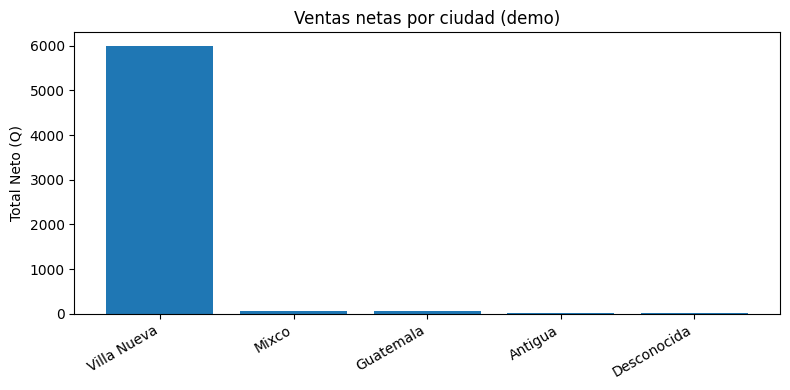

In [13]:
# Gráfico rápido
plt.figure(figsize=(8,4))
plt.bar(res_ciudad["Ciudad"], res_ciudad["TotalNeto"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("Total Neto (Q)")
plt.title("Ventas netas por ciudad (demo)")
plt.tight_layout()
plt.show()


In [14]:
# Resumen por Categoría
res_categoria = df_after.groupby("Categoria", as_index=False)["TotalNeto"].sum().sort_values("TotalNeto", ascending=False)
res_categoria


,Categoria,TotalNeto
1,Lácteos,6018.50
0,Bebidas,92.50
2,Snacks,44.75


## 7) Exportación (opcional)

In [15]:
output_path = "datos_limpios_demo.csv"
df_after.to_csv(output_path, index=False, encoding="utf-8")
print("Archivo exportado:", output_path)


Archivo exportado: datos_limpios_demo.csv
